# Miniature adaptive monotherapy screen — custom Gibbs

Repeat notebook 1.0 with `BayesianFixedDoseModel(sampler=GibbsSampler(...))`, preserving response preparation, random seed and RNG call order, nested 2/6/10 backgrounds, a supported pool capped at 256 compounds, 16 initial target observations, and ten rounds of eight acquisitions. More negative LFC means stronger killing. The fixed hit set is the pool's lowest-LFC ceil(10% × pool size), ties broken by compound ID; retrieval includes the initial measurements.

The current Gibbs configuration uses four chains, 200 warmup sweeps and 100 retained posterior samples per chain at thinning 2. These settings are not matched to notebook 1.0's lightweight NUTS settings and do not demonstrate convergence. Gibbs does not use `target_accept` or `max_treedepth`.

The v2 `ExperimentLogger` records dataset/split provenance, ordered fit inputs, state/action lineage, frozen selector predictions, ordered acquisitions, evaluations, and checksum-verified NetCDF traces. A separate bundle under `output/demo_sampler_comparison/gibbs/logger_v2` preserves both the historical Gibbs exports and notebook 1.0's bundle; reruns append fresh experiment IDs without deleting data.

The simulator and selectors are unchanged. Hidden target responses are used only for reveals and retrospective scoring, not model fitting or selection before they are revealed. Random selection still fits through the same interface, but never calls `predict`. There is no fit after the final acquisition: the last fit sees 88 target observations; final retrieval is scored at 96.

After fitting, reopen the bundle, verify every trace artifact, compare each final trace with its live model, and reconstruct retrieval trajectories from registered responses and saved acquisitions/evaluations. The plot uses reloaded metrics. Reloading supports posterior analysis, not model reconstruction or resumed sampling. Historical CSV exports consumed by notebook 1.2 are not refreshed by this v2 workflow. This is a single-target demonstration, not general efficacy evidence.

In [1]:
from pathlib import Path
import sys
import json
import hashlib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import xarray as xr

from nbutils.batchie_mono.factorization_model import BayesianFixedDoseModel
from nbutils.batchie_mono.gibbs import GibbsSampler
from nbutils.batchie_mono.simulation import run_simulation
from nbutils.batchie_mono.model_acquisition import PredictedLowestSelector, RandomSelector
from nbutils.batchie_mono.sampling import SamplingConfig
from nbutils.batchie_mono.spec import ModelSpec
from nbutils.batchie_mono.logger import ExperimentLogger

# Scripts start from their own location; notebooks start from the working directory.
start_path = Path(__file__).resolve().parent if "__file__" in globals() else Path.cwd().resolve()
repo_root = next(path for path in [start_path, *start_path.parents]
                 if (path / "pyproject.toml").is_file()
                 and (path / "analysis").is_dir()
                 and (path / "data").is_dir())

backend = "gibbs"
model_spec = ModelSpec(rank=4)
sampling_config = SamplingConfig(
    burnin=200,
    posterior_samples=100,
    thin=2,
    chains=4,
    cores=16,
    blas_cores=1,
)
sampler_settings = sampling_config.model_dump()

output_dir = repo_root / "output/demo_sampler_comparison" / backend
output_dir.mkdir(parents=True, exist_ok=True)
print(f"Backend: {backend}; Python: {sys.executable}; model: {model_spec.model_dump()}; settings: {sampler_settings}")

/home/weishanli/anaconda3/envs/dspy-litl-env/lib/python3.11/site-packages/arviz/__init__.py:50: FutureWarning: 
ArviZ is undergoing a major refactor to improve flexibility and extensibility while maintaining a user-friendly interface.
Some upcoming changes may be backward incompatible.
For details and migration guidance, visit: https://python.arviz.org/en/latest/user_guide/migration_guide.html
  warn(


Backend: gibbs; Python: /home/weishanli/anaconda3/envs/dspy-litl-env/bin/python; model: {'rank': 4, 'prior_shape': 1.1, 'prior_rate': 1.1, 'global_precision': 0.01}; settings: {'burnin': 200, 'posterior_samples': 100, 'thin': 2, 'chains': 4, 'seed': 0, 'cores': 16, 'blas_cores': 1}


In [2]:
response_file = repo_root / "data/secondary-screen-observed-response-long.parquet"
if not response_file.exists():
    raise FileNotFoundError(f"Response file does not exist: {response_file}")
keys = ["ModelID", "broad_id", "dose"]
responses = pd.read_parquet(response_file, columns=[*keys, "logfold_change"])
responses.head()

,ModelID,broad_id,dose,logfold_change
0,ACH-000001,BRD-K44408410-001-17-6,0.00061,0.164948
1,ACH-000001,BRD-K44408410-001-17-6,0.00244,-0.647867
2,ACH-000001,BRD-K44408410-001-17-6,0.03910,-0.241189
3,ACH-000001,BRD-K44408410-001-17-6,0.15625,0.176981
4,ACH-000001,BRD-K44408410-001-17-6,0.62500,-0.223823


In [3]:
# Identical response-blind selection and RNG call order to notebook 1.0.
seed = 0
rng = np.random.default_rng(seed)
initial_size, batch_size, iterations = 16, 8, 10
pool_size = 256
background_counts = [2, 6, 10]
fixed_dose = responses.groupby("dose").size().idxmax()
fixed = (
    responses.loc[responses["dose"].eq(fixed_dose)]
    .dropna(subset=[*keys, "logfold_change"])
    .groupby(keys, as_index=False)["logfold_change"].mean()
)
coverage = fixed.groupby("ModelID")["broad_id"].nunique()
eligible = coverage[coverage >= initial_size + batch_size * iterations].index
target_model = str(rng.choice(eligible))
other_models = rng.choice(coverage.index[coverage.index != target_model],
                          size=max(background_counts), replace=False)
smallest_background = fixed[fixed["ModelID"].isin(other_models[:2])]
target_responses = fixed[
    fixed["ModelID"].eq(target_model)
    & fixed["broad_id"].isin(smallest_background["broad_id"])
]
target_responses = target_responses.sample(
    n=min(pool_size, len(target_responses)), random_state=seed,
).reset_index(drop=True)
if len(target_responses) < initial_size + batch_size * iterations:
    raise ValueError("Not enough target responses to match the required pool size.")
backgrounds = {
    count: fixed[
        fixed["ModelID"].isin(other_models[:count])
        & fixed["broad_id"].isin(target_responses["broad_id"])
    ].copy()
    for count in background_counts
}
initial_compounds = target_responses.sample(n=initial_size, random_state=seed)["broad_id"].tolist()
print(f"Target: {target_model} | fixed dose: {fixed_dose:g}")
print(f"Background models: {other_models}")
print(f"Shared pool: {len(target_responses)} compounds (cap {pool_size}) | backgrounds: {background_counts}")
print(f"Shared initial observations: {initial_size} | acquisition: {iterations} × {batch_size}")

Target: ACH-000922 | fixed dose: 2.5
Background models: ['ACH-000701' 'ACH-000086' 'ACH-000569' 'ACH-000320' 'ACH-000362'
 'ACH-000211' 'ACH-000018' 'ACH-000886' 'ACH-000046' 'ACH-000724']
Shared pool: 154 compounds (cap 256) | backgrounds: [2, 6, 10]
Shared initial observations: 16 | acquisition: 10 × 8


In [4]:
def make_model():
    """Create an independent Gibbs model for one simulation trajectory."""
    return BayesianFixedDoseModel(
        sampler=GibbsSampler(config=sampling_config),
        spec=model_spec,
        prediction_seed=seed,
    )

# Hash the source once; run_simulation registers prepared responses and fit inputs.
source_hash = hashlib.sha256()
with response_file.open("rb") as source:
    for chunk in iter(lambda: source.read(1024 * 1024), b""):
        source_hash.update(chunk)
provenance = {
    "dataset": {
        "source": str(response_file.relative_to(repo_root)),
        "source_sha256": source_hash.hexdigest(),
        "preparation": "miniature-background-ablation-v1",
        "recipe": [
            "most frequent dose; drop missing core values; mean per response key",
            "seeded eligible target then nested background sampling without replacement",
            "pool supported by first two backgrounds; seeded pool and initial sampling",
        ],
    },
    "data_seed": seed,
    "target_model": target_model,
    "fixed_dose": float(fixed_dose),
    "background_order": other_models.tolist(),
    "background_counts": background_counts,
    "pool_size": pool_size,
    "initial_size": initial_size,
    "backend": backend,
    "versions": {"numpy": np.__version__, "pandas": pd.__version__},
}
# Isolate v2 artifacts from historical exports and the PyMC bundle; never delete on rerun.
db_path = output_dir / "logger_v2" / "miniature_screen_gibbs_v2.sqlite"
experiment_name = "miniature-background-ablation-gibbs"
runs = []
fitted_models = {}  # Only the last model per trajectory is needed for reload checks.
random_background_count = min(background_counts)

with ExperimentLogger(db_path) as logger:
    for count in background_counts:
        model = make_model()
        result = run_simulation(
            background=backgrounds[count], target_responses=target_responses,
            initial_compounds=initial_compounds, model=model,
            selector=PredictedLowestSelector(), batch_size=batch_size, iterations=iterations,
            logger=logger, experiment_name=experiment_name,
            metadata={**provenance, "background_cells": count},
        )
        fitted_models[result["trajectory_id"].iloc[0]] = model
        result["background_cells"] = count
        result["background_measurements"] = len(backgrounds[count])
        runs.append(result)
        print(f"{count} background lines: retrieved {result.iloc[-1]['top_10pct_retrieval']:.1%} of top hits")

    model = make_model()
    random_baseline = run_simulation(
        background=backgrounds[random_background_count], target_responses=target_responses,
        initial_compounds=initial_compounds, model=model,
        selector=RandomSelector(seed=seed), batch_size=batch_size, iterations=iterations,
        logger=logger, experiment_name=experiment_name,
        metadata={**provenance, "background_cells": random_background_count,
                  "selector_seed": seed},
    )
    fitted_models[random_baseline["trajectory_id"].iloc[0]] = model

random_baseline["background_cells"] = random_background_count
random_baseline["background_measurements"] = len(backgrounds[random_background_count])
metrics = pd.concat([*runs, random_baseline], ignore_index=True)
print(f"Saved {len(fitted_models) * iterations} fits and retrieval metrics to {db_path}")
metrics.groupby(["selector", "background_cells"]).tail(1)

2 background lines: retrieved 100.0% of top hits
6 background lines: retrieved 100.0% of top hits
10 background lines: retrieved 100.0% of top hits
Saved 40 fits and retrieval metrics to /home/weishanli/Waylab/PRISM_Agent_LITL_experiments/output/demo_sampler_comparison/gibbs/logger_v2/miniature_screen_gibbs_v2.sqlite


,selector,iteration,compounds_seen,top_hits_found,top_hits_total,top_10pct_retrieval,trajectory_id,background_cells,background_measurements
10,predicted_lowest,10,96,16,16,1.0000,8a0f24e5-2b8f-477c-9de0-60514322249c,2,308
21,predicted_lowest,10,96,16,16,1.0000,a47ee109-656d-4019-9a88-bf2affd17ed5,6,924
32,predicted_lowest,10,96,16,16,1.0000,331e17b6-8c46-4707-a6f2-7b82216ceddd,10,1540
43,random,10,96,11,16,0.6875,8bfe94a3-b064-4871-95ea-839454138795,2,308


In [5]:
# Reopen the closed v2 bundle, restricting checks to this invocation's trajectories.
def replay_retrieval_metrics(saved, seen, hit_ids):
    """Recompute retrieval and reject metrics inconsistent with revealed IDs."""
    replayed = {
        "compounds_seen": len(seen),
        "top_hits_found": len(seen & hit_ids),
        "top_hits_total": len(hit_ids),
        "top_10pct_retrieval": len(seen & hit_ids) / len(hit_ids),
    }
    for metric in ("compounds_seen", "top_hits_found", "top_hits_total"):
        np.testing.assert_equal(saved[metric], replayed[metric], err_msg=metric)
    np.testing.assert_allclose(
        saved["top_10pct_retrieval"], replayed["top_10pct_retrieval"],
        rtol=1e-12, atol=0, err_msg="top_10pct_retrieval",
    )
    return {**saved, **replayed}


reloaded_records = []
reload_checks = []
trajectory_ids = metrics["trajectory_id"].unique().tolist()
with ExperimentLogger(db_path) as logger:
    for trajectory_id in trajectory_ids:
        experiment = logger.one(
            "SELECT * FROM experiments WHERE experiment_id=?", (trajectory_id,),
        )
        config = json.loads(experiment["config"])
        context = config["provenance"]
        actions = pd.DataFrame(logger.rows(
            "SELECT a.*, s.sequence FROM actions a "
            "JOIN experiment_states s ON s.state_id=a.output_state_id "
            "WHERE a.experiment_id=? ORDER BY s.sequence", (trajectory_id,),
        ))
        fits = actions[actions["kind"].eq("fit")]
        acquisitions = actions[actions["kind"].eq("acquire")]

        # Verify all trace checksums and compare the final trace with the live fit.
        for fit_id in fits["action_id"]:
            for artifact in logger.artifact_records(fit_id):
                logger.artifacts.verify(artifact)
        fit_metadata, trace = logger.load_run(fits.iloc[-1]["action_id"])
        original = fitted_models[trajectory_id].inference_data_
        np.testing.assert_equal(trace.groups(), original.groups())
        for group in trace.groups():
            xr.testing.assert_identical(trace[group], original[group])

        # Reconstruct the fixed hit set from registered target responses.
        target = pd.DataFrame(logger.rows(
            "SELECT r.* FROM responses r JOIN split_memberships m USING(response_id) "
            "WHERE m.split_id=? AND r.cell_id=?",
            (experiment["split_id"], context["target_model"]),
        ))
        hit_ids = set(target.sort_values(["value", "drug_id"]).head(
            max(1, int(np.ceil(0.1 * len(target)))))["response_id"])
        initial_state = logger.one(
            "SELECT * FROM experiment_states WHERE experiment_id=? AND sequence=0",
            (trajectory_id,),
        )
        seen = logger.revealed_ids(initial_state["data_state_id"]) & set(target["response_id"])
        rows = [replay_retrieval_metrics(config["initial_metrics"], seen, hit_ids)]
        for action in acquisitions.to_dict("records"):
            selected = logger.rows(
                "SELECT * FROM acquisition_items WHERE action_id=? ORDER BY rank",
                (action["action_id"],),
            )
            seen.update(item["response_id"] for item in selected)
            values = {row["metric"]: row["value"] for row in logger.rows(
                "SELECT * FROM evaluations WHERE action_id=? AND scope='simulation'",
                (action["action_id"],),
            )}
            rows.append({"selector": config["selector"],
                         **replay_retrieval_metrics(values, seen, hit_ids)})
        background_measurements = len(logger.rows(
            "SELECT r.response_id FROM responses r JOIN split_memberships m USING(response_id) "
            "WHERE m.split_id=? AND m.role='initial' AND r.cell_id!=?",
            (experiment["split_id"], context["target_model"]),
        ))
        for row in rows:
            row.update(trajectory_id=trajectory_id,
                       background_cells=context["background_cells"],
                       background_measurements=background_measurements)
        reloaded_records.extend(rows)
        reload_checks.append({
            "trajectory_id": trajectory_id, "selector": config["selector"],
            "background_cells": context["background_cells"],
            "fits": len(fits), "acquisitions": len(acquisitions),
            "trace_equal": True, "retrieval_replayed": True,
        })
    saved_trace = trace  # Eagerly loaded; usable after the connection closes.

reloaded_metrics = pd.DataFrame(reloaded_records)[metrics.columns]
pd.testing.assert_frame_equal(
    reloaded_metrics.reset_index(drop=True), metrics.reset_index(drop=True),
    check_dtype=False, rtol=1e-12, atol=0,
 )
pd.DataFrame(reload_checks)

,trajectory_id,selector,background_cells,fits,acquisitions,trace_equal,retrieval_replayed
0,8a0f24e5-2b8f-477c-9de0-60514322249c,predicted_lowest,2,10,10,True,True
1,a47ee109-656d-4019-9a88-bf2affd17ed5,predicted_lowest,6,10,10,True,True
2,331e17b6-8c46-4707-a6f2-7b82216ceddd,predicted_lowest,10,10,10,True,True
3,8bfe94a3-b064-4871-95ea-839454138795,random,2,10,10,True,True


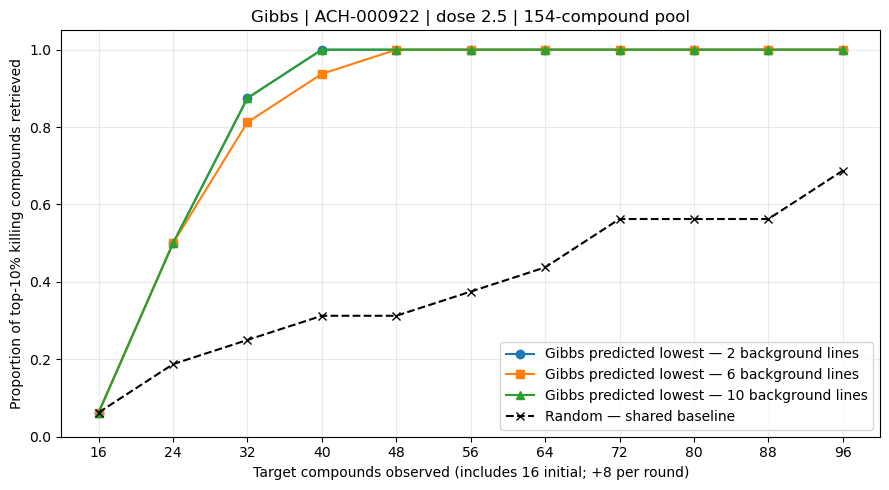

In [6]:
# Plot persisted/reloaded trajectories rather than the original in-memory results.
fig, ax = plt.subplots(figsize=(9, 5))
markers = {2: "o", 6: "s", 10: "^"}
for count, trajectory in reloaded_metrics[reloaded_metrics.selector.eq("predicted_lowest")].groupby("background_cells"):
    ax.plot(trajectory.compounds_seen, trajectory.top_10pct_retrieval,
            marker=markers[count], label=f"Gibbs predicted lowest — {count} background lines")
reloaded_random = reloaded_metrics[reloaded_metrics.selector.eq("random")]
ax.plot(reloaded_random.compounds_seen, reloaded_random.top_10pct_retrieval,
        color="black", linestyle="--", marker="x", label="Random — shared baseline")
ax.set(xlabel=f"Target compounds observed (includes {initial_size} initial; +{batch_size} per round)",
       ylabel="Proportion of top-10% killing compounds retrieved",
       title=f"Gibbs | {target_model} | dose {fixed_dose:g} | {len(target_responses)}-compound pool",
       ylim=(0, 1.05), xticks=reloaded_random.compounds_seen)
ax.grid(alpha=.25)
ax.legend()
fig.tight_layout()
fig.savefig(db_path.parent / "retrieval.png", dpi=150)
plt.show()